# SafetyCam: Modeling Deteksi APD (versi lengkap)

Tujuan: model YOLO11 yang **akurat** mendeteksi APD pekerja konstruksi, terutama
**pelanggaran** (`no_helmet`, `no_gloves`, `no_boots`, `no_goggle`), memakai dataset
[Construction-PPE](https://docs.ultralytics.com/datasets/detect/construction-ppe/).

Strategi supaya modelnya bagus:

| Langkah | Kenapa |
|---|---|
| 1. Analisis dataset | cek jumlah per kelas, kualitas label, kebocoran antar split, ukuran objek |
| 2. Repeat-factor sampling | kelas pelanggaran jarang, jadi gambarnya diulang supaya model lebih sering melihatnya |
| 3. Eksperimen pembanding | bandingkan ukuran model dan resolusi dengan setting yang sama, pilih berdasarkan data |
| 4. Training final lebih lama | konfigurasi terbaik dilatih ulang lebih lama, dengan early stopping |
| 5. Evaluasi di data **test** | angka jujur dari data yang tidak dipakai saat memilih model |
| 6. Threshold per kelas | `no_*` dibuat lebih sensitif (recall), kelas lain seimbang |
| 7. Evaluasi kepatuhan | apakah status **PELANGGARAN / AMAN** per gambar benar? |
| 8. Analisis error | lihat pelanggaran yang terlewat, untuk tahu apa yang perlu diperbaiki |
| 9. Export | ONNX untuk website |

Pemakaian:
- Kernel: **Python (IRIS)**.
- Jalankan dari folder `safetycam/training/`.
- Hasil training yang sudah ada otomatis dipakai ulang, jadi notebook aman dijalankan ulang.

## 1. Setup

In [25]:
import hashlib, json, math, random, shutil, subprocess, sys, time
from collections import Counter, defaultdict
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import yaml
from IPython.display import Image as IPImage, display
from PIL import Image
from ultralytics import YOLO
from ultralytics.data.utils import exif_size

import compliance
import dataset

ROOT = Path.cwd()
assert (ROOT / "train.py").exists(), "Jalankan notebook ini dari folder safetycam/training/"
RUNS = ROOT / "runs" / "notebook"
OUT = ROOT / "results" / "notebook"
OUT.mkdir(parents=True, exist_ok=True)

SEED = 0
random.seed(SEED); np.random.seed(SEED)
DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("Python", sys.version.split()[0], "| torch", torch.__version__, "| device:", DEVICE)
if DEVICE == 0:
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name}, {p.total_memory / 1e9:.0f} GB")
pd.set_option("display.precision", 3)

Python 3.14.4 | torch 2.11.0+cu128 | device: 0
GPU: NVIDIA GeForce RTX 5090, 34 GB


### Konfigurasi
Semua angka yang bisa diubah ada di sini.

In [26]:
CFG = dict(
    exp_epochs=80,         # epoch per eksperimen pembanding (cukup untuk membandingkan)
    final_epochs=200,      # epoch training final
    patience_exp=30,       # early stopping
    patience_final=50,
    batch=32,              # RTX 5090 32 GB: aman sampai 64 untuk n/s di 640
    workers=8,             # kalau DataLoader error di Windows, ganti 0
    cache="ram",           # dataset kecil (~1.4k gambar), muat semua di RAM
    rfs_threshold=0.3,     # kelas yang muncul di < 30% gambar akan di-oversample
    rfs_max_repeat=4,      # maksimal satu gambar diulang 4x
)
VIOLATION_CLASSES = ["no_helmet", "no_gloves", "no_boots", "no_goggle"]  # dipakai skor eksperimen
# Dataset tidak punya kelas "no_vest"; kotak "none" ada di badan = tidak memakai rompi.
ALARM_CLASSES = VIOLATION_CLASSES + ["none"]  # semua kelas pelanggaran (threshold, warna, analisis)

# Augmentasi. Default Ultralytics + sedikit penyesuaian untuk foto proyek.
HYP = dict(
    optimizer="auto", cos_lr=True, amp=True,
    mosaic=1.0, close_mosaic=10,   # mosaic dimatikan 10 epoch terakhir supaya stabil
    mixup=0.1,                     # membantu generalisasi di dataset kecil
    scale=0.5, translate=0.1, degrees=0.0, fliplr=0.5,
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,  # variasi cahaya (terik, mendung, indoor)
)

## 2. Dataset

Dataset terdownload otomatis ke `training/datasets/` pada run pertama (sekitar 180 MB).

In [27]:
DATA_YAML = dataset.prepare()
cfg = yaml.safe_load(Path(DATA_YAML).read_text(encoding="utf-8"))
NAMES = cfg["names"] if isinstance(cfg["names"], list) else [cfg["names"][i] for i in sorted(cfg["names"])]
DATA_ROOT = Path(cfg["path"])
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def img_files(split):
    d = DATA_ROOT / cfg[split]
    return sorted(p for p in d.rglob("*") if p.suffix.lower() in IMG_EXT) if d.exists() else []

def label_path(img):
    parts = list(Path(img).parts)
    i = len(parts) - 1 - parts[::-1].index("images")
    parts[i] = "labels"
    return Path(*parts).with_suffix(".txt")

def read_labels(img):
    f = label_path(img)
    if not f.exists():
        return np.zeros((0, 5))
    rows = [list(map(float, l.split()[:5])) for l in f.read_text().splitlines() if l.strip()]
    return np.array(rows).reshape(-1, 5)

SPLITS = {s: img_files(s) for s in ("train", "val", "test") if cfg.get(s)}
LABELS = {s: {p: read_labels(p) for p in files} for s, files in SPLITS.items()}
TEST_SPLIT = "test" if SPLITS.get("test") else "val"
print("Kelas:", NAMES)
print({s: len(f) for s, f in SPLITS.items()}, "| split evaluasi akhir:", TEST_SPLIT)

Kelas: ['helmet', 'gloves', 'vest', 'boots', 'goggles', 'none', 'Person', 'no_helmet', 'no_goggle', 'no_gloves', 'no_boots']
{'train': 1132, 'val': 143, 'test': 141} | split evaluasi akhir: test


### 2.1 Jumlah objek per kelas

split,test,train,val,% gambar train
kelas,,,,
helmet,192,1341,201,73.3
gloves,163,1146,136,49.6
vest,178,1269,171,73.1
boots,211,1235,151,46.8
goggles,52,419,47,34.0
none,65,651,81,30.7
Person,236,1770,239,94.3
no_helmet,40,400,45,20.5
no_goggle,33,337,41,19.1


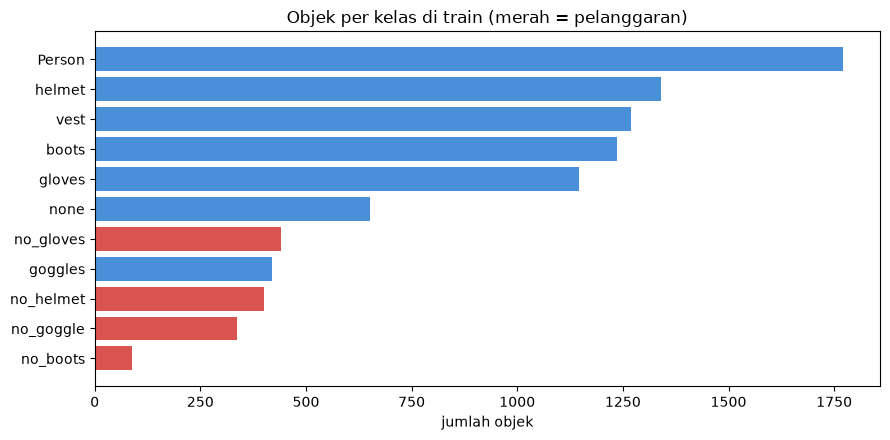

In [28]:
rows = []
for s, lab in LABELS.items():
    inst, imgs = Counter(), Counter()
    for arr in lab.values():
        cls = arr[:, 0].astype(int).tolist()
        inst.update(cls); imgs.update(set(cls))
    for i, n in enumerate(NAMES):
        rows.append({"split": s, "kelas": n, "objek": inst[i], "gambar": imgs[i]})
stats = pd.DataFrame(rows)

table = stats.pivot(index="kelas", columns="split", values="objek").loc[NAMES]
table["% gambar train"] = (stats[stats.split == "train"].set_index("kelas").loc[NAMES, "gambar"] / len(SPLITS["train"]) * 100).round(1)
display(table)

tr = stats[stats.split == "train"].sort_values("objek")
plt.figure(figsize=(9, 4.5))
plt.barh(tr.kelas, tr.objek, color=["#d9534f" if k.startswith("no_") else "#4a90d9" for k in tr.kelas])
plt.title("Objek per kelas di train (merah = pelanggaran)"); plt.xlabel("jumlah objek")
plt.tight_layout(); plt.savefig(OUT / "class_distribution.png", dpi=120); plt.show()

### 2.2 Kualitas label & kebocoran antar split
Gambar yang sama di train dan test membuat skor test terlihat lebih bagus dari kenyataan.

In [29]:
issues = Counter()
for s, lab in LABELS.items():
    for p, arr in lab.items():
        if not label_path(p).exists():
            issues[f"{s}: file label hilang"] += 1
        elif len(arr) == 0:
            issues[f"{s}: label kosong (gambar background)"] += 1
        if len(arr) and ((arr[:, 1:] < 0) | (arr[:, 1:] > 1)).any():
            issues[f"{s}: koordinat di luar 0-1"] += 1
        if len(arr) and (arr[:, 3] * arr[:, 4] < 1e-5).any():
            issues[f"{s}: kotak sangat kecil (<0.001% gambar)"] += 1
print("Masalah label:", dict(issues) or "tidak ada")

hashes = defaultdict(list)
for s, files in SPLITS.items():
    for p in files:
        hashes[hashlib.md5(p.read_bytes()).hexdigest()].append(s)
dups = [v for v in hashes.values() if len(v) > 1]
leak = Counter(tuple(sorted(set(v))) for v in dups if len(set(v)) > 1)
print("Gambar identik:", len(dups), "| bocor antar split:", dict(leak) or "tidak ada")

Masalah label: tidak ada
Gambar identik: 0 | bocor antar split: tidak ada


### 2.3 Ukuran objek
Objek kecil (sisi < 32 px saat gambar di-resize ke 640) sulit dideteksi. Kalau persentasenya besar,
resolusi lebih tinggi (`imgsz=960`) biasanya membantu. Angkanya perkiraan, karena dihitung dari luas kotak.

,median sisi (px@640),% objek kecil
kelas,,
helmet,70.5,10.7
gloves,53.4,7.3
vest,161.4,1.3
boots,72.6,5.9
goggles,52.2,7.2
none,126.9,5.7
Person,290.1,0.1
no_helmet,72.4,6.8
no_goggle,38.9,38.9


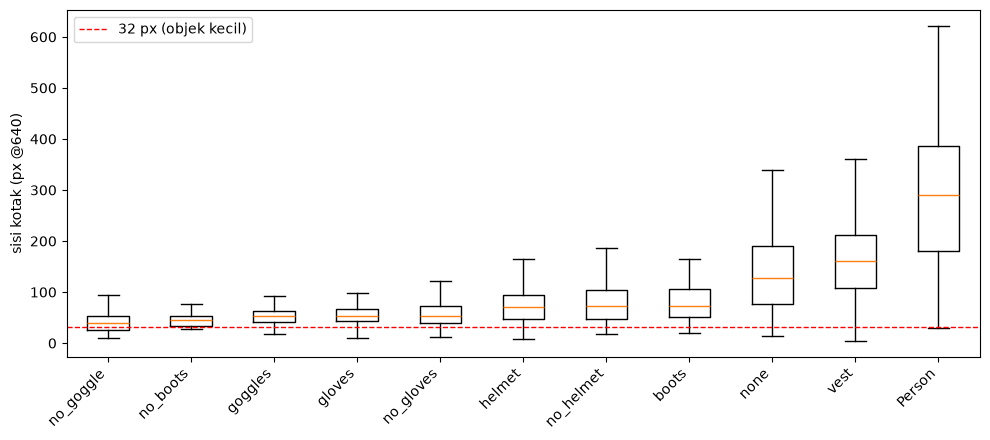

In [30]:
size_rows = []
for p, arr in LABELS["train"].items():
    if not len(arr):
        continue
    W, H = exif_size(Image.open(p))      # ukuran asli (setelah rotasi EXIF)
    s = 640 / max(W, H)                  # YOLO: sisi terpanjang di-resize ke 640
    for c, _, _, w, h in arr:
        bw, bh = w * W * s, h * H * s    # lebar & tinggi kotak dalam px @640
        size_rows.append({"kelas": NAMES[int(c)], "sisi_px": math.sqrt(bw * bh)})

sizes = pd.DataFrame(size_rows)
size_tbl = sizes.groupby("kelas")["sisi_px"].agg(
    median="median", kecil_pct=lambda x: (x < 32).mean() * 100
).loc[[n for n in NAMES if n in set(sizes.kelas)]].round(1)
display(size_tbl.rename(columns={"median": "median sisi (px@640)", "kecil_pct": "% objek kecil"}))

order = size_tbl.sort_values("median").index.tolist()
plt.figure(figsize=(10, 4.5))
plt.boxplot([sizes.loc[sizes.kelas == k, "sisi_px"] for k in order], tick_labels=order, showfliers=False)
plt.axhline(32, ls="--", c="r", lw=1, label="32 px (objek kecil)")
plt.xticks(rotation=45, ha="right"); plt.ylabel("sisi kotak (px @640)"); plt.legend()
plt.tight_layout(); plt.show()

### 2.4 Contoh label pelanggaran

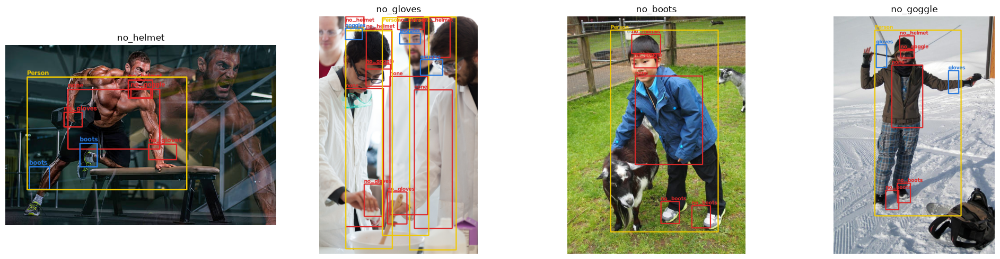

In [31]:
def draw_boxes(img_rgb, dets, color_fn, is_gt=False):
    img = img_rgb.copy()
    s = max(img.shape[:2]) / 640           # skala garis & teks mengikuti resolusi gambar
    lw, fs = max(2, round(2 * s)), 0.5 * max(1.0, s)
    for name, conf, (x1, y1, x2, y2) in dets:
        col = color_fn(name)
        x1, y1, x2, y2 = map(int, (x1, y1, x2, y2))
        cv2.rectangle(img, (x1, y1), (x2, y2), col, lw)
        text = name if is_gt else f"{name} {conf:.2f}"
        cv2.putText(img, text, (x1, max(int(14 * s), y1 - lw - 2)), cv2.FONT_HERSHEY_SIMPLEX, fs, col, lw)
    return img

def color_of(name):
    if name in ALARM_CLASSES: return (220, 40, 40)
    if name == "Person": return (240, 200, 0)
    return (40, 120, 220)

def gt_detections(img_path):
    w, h = exif_size(Image.open(img_path))  # ukuran setelah rotasi EXIF, sama seperti Ultralytics
    return [
        (NAMES[int(c)], 1.0, ((xc - bw / 2) * w, (yc - bh / 2) * h, (xc + bw / 2) * w, (yc + bh / 2) * h))
        for c, xc, yc, bw, bh in read_labels(img_path)
    ]

def load_rgb(p):
    return cv2.cvtColor(cv2.imread(str(p)), cv2.COLOR_BGR2RGB)

rng = random.Random(SEED)
fig, axes = plt.subplots(1, len(VIOLATION_CLASSES), figsize=(5 * len(VIOLATION_CLASSES), 5))
for ax, cname in zip(axes, VIOLATION_CLASSES):
    ci = NAMES.index(cname)
    cands = [p for p, a in LABELS["train"].items() if (a[:, 0] == ci).any()]
    ax.axis("off")
    if cands:
        p = rng.choice(cands)
        ax.imshow(draw_boxes(load_rgb(p), gt_detections(p), color_of, is_gt=True)); ax.set_title(cname)
plt.tight_layout(); plt.show()

## 3. Menangani kelas jarang: Repeat-Factor Sampling

Teknik ini berasal dari LVIS. Untuk setiap kelas $c$ dengan frekuensi gambar $f_c$, faktor ulangnya adalah
$r_c = \max(1, \sqrt{t / f_c})$. Setiap gambar diulang sebanyak $r_c$ terbesar dari kelas yang ada di dalamnya.
Hasilnya, gambar berisi pelanggaran lebih sering muncul saat training, **tanpa** mengubah data val/test.

In [32]:
def repeat_factors(labels, t, max_r):
    n = len(labels)
    img_cls = {p: set(a[:, 0].astype(int).tolist()) for p, a in labels.items()}
    freq = Counter(c for cs in img_cls.values() for c in cs)
    r_c = {c: max(1.0, math.sqrt(t / (freq[c] / n))) for c in freq}
    return {p: min(max_r, max([r_c[c] for c in cs], default=1.0)) for p, cs in img_cls.items()}, r_c

factors, r_c = repeat_factors(LABELS["train"], CFG["rfs_threshold"], CFG["rfs_max_repeat"])
rs = np.random.default_rng(SEED)
train_list = []
for p, r in factors.items():
    k = int(math.floor(r)) + int(rs.random() < r - math.floor(r))  # stochastic rounding
    train_list += [str(p)] * k
rs.shuffle(train_list)

RFS_TXT = DATA_ROOT / "train_rfs.txt"
RFS_TXT.write_text("\n".join(train_list) + "\n", encoding="utf-8")
rfs_cfg = {k: v for k, v in cfg.items()}
rfs_cfg["train"] = str(RFS_TXT)
RFS_YAML = Path(DATA_YAML).with_name("construction-ppe-rfs.yaml")
RFS_YAML.write_text(yaml.safe_dump(rfs_cfg, sort_keys=False), encoding="utf-8")
DATA = {"base": DATA_YAML, "rfs": str(RFS_YAML)}

after = Counter()
for p in train_list:
    after.update(read_labels(p)[:, 0].astype(int).tolist())
before = stats[stats.split == "train"].set_index("kelas")["objek"]
cmp = pd.DataFrame({
    "faktor kelas": {NAMES[c]: round(v, 2) for c, v in r_c.items()},
    "objek sebelum": before,
    "objek sesudah": {NAMES[c]: n for c, n in after.items()},
}).loc[NAMES].fillna(0)
cmp["naik x"] = (cmp["objek sesudah"] / cmp["objek sebelum"].clip(lower=1)).round(2)
print(f"Gambar train: {len(factors)} -> {len(train_list)} entri")
cmp

Gambar train: 1132 -> 1260 entri


,faktor kelas,objek sebelum,objek sesudah,naik x
helmet,1.00,1341,1349,1.01
gloves,1.00,1146,1166,1.02
vest,1.00,1269,1269,1.00
boots,1.00,1235,1263,1.02
goggles,1.00,419,438,1.05
none,1.00,651,889,1.37
Person,1.00,1770,2022,1.14
no_helmet,1.21,400,618,1.54
no_goggle,1.25,337,520,1.54
no_gloves,1.34,442,698,1.58


## 4. Eksperimen pembanding

Setiap konfigurasi dilatih dengan epoch dan augmentasi yang sama, lalu dinilai di **val**.

**Skor** = rata-rata dari `mAP50-95` (ketepatan kotak) dan `recall pelanggaran` (berapa persen `no_*` yang tertangkap).
Recall pelanggaran ikut dihitung karena pelanggaran yang terlewat adalah kesalahan paling berbahaya.

`web_ok` menandai model yang bisa dipakai website (input 640). Ukuran ONNX kira-kira: n ≈ 10 MB, s ≈ 37 MB, m ≈ 80 MB.
Makin besar, makin lambat di browser.

Eksperimen dijalankan **satu per satu**: jalankan satu langkah, lihat hasilnya, baru putuskan lanjut.

In [33]:
def summarize(model, metrics):
    box = metrics.box
    per = {}
    for i, c in enumerate(box.ap_class_index):
        p, r, ap50, ap = box.class_result(i)
        per[model.names[int(c)]] = dict(precision=float(p), recall=float(r), mAP50=float(ap50), mAP50_95=float(ap))
    viol = [per[c]["recall"] for c in VIOLATION_CLASSES if c in per]
    return dict(
        precision=float(box.mp), recall=float(box.mr), mAP50=float(box.map50), mAP50_95=float(box.map),
        violation_recall=float(np.mean(viol)) if viol else float("nan"), per_class=per,
    )


def train_run(name, model, imgsz, data, epochs, patience, **extra):
    run_dir = RUNS / name
    summary_file = run_dir / "summary.json"
    if summary_file.exists():
        print(f"[{name}] sudah pernah dilatih, pakai hasil lama")
        return json.loads(summary_file.read_text())
    t0 = time.time()
    batch = CFG["batch"] if imgsz <= 640 else max(8, CFG["batch"] // 2)
    last = run_dir / "weights" / "last.pt"
    if last.exists():
        # training sebelumnya terputus (misalnya PC mati), lanjutkan dari epoch terakhir
        print(f"[{name}] checkpoint ditemukan, melanjutkan training")
        try:
            YOLO(str(last)).train(resume=True)
        except AssertionError:
            print(f"[{name}] training sebenarnya sudah selesai, langsung evaluasi")
    else:
        args = dict(
            data=DATA[data], imgsz=imgsz, epochs=epochs, patience=patience, batch=batch,
            device=DEVICE, workers=CFG["workers"], cache=CFG["cache"],
            project=str(RUNS), name=name, exist_ok=True, seed=SEED, deterministic=True, plots=True,
        )
        args.update(HYP); args.update(extra)
        YOLO(model).train(**args)
    best = run_dir / "weights" / "best.pt"
    bm = YOLO(str(best))
    met = bm.val(data=DATA_YAML, split="val", imgsz=imgsz, batch=batch, device=DEVICE, plots=False,
                 project=str(RUNS), name=name + "_val", exist_ok=True, verbose=False)
    s = summarize(bm, met)
    s.update(name=name, model=model, imgsz=imgsz, data=data, epochs=epochs, weights=str(best),
             minutes=round((time.time() - t0) / 60, 1), web_ok=imgsz == 640)
    summary_file.write_text(json.dumps(s, indent=2))
    return s

In [34]:
EXPERIMENTS = {
    "n640_base": dict(model="yolo11n.pt", imgsz=640, data="base"),
    "n640_rfs":  dict(model="yolo11n.pt", imgsz=640, data="rfs"),
    "s640_rfs":  dict(model="yolo11s.pt", imgsz=640, data="rfs"),
    "m640_rfs":  dict(model="yolo11m.pt", imgsz=640, data="rfs"),
    "s960_rfs":  dict(model="yolo11s.pt", imgsz=960, data="rfs"),
}
exp_results = {}   # diisi berurutan sesuai run yang dijalankan

def run_exp(name, **kw):
    cfg_e = {**EXPERIMENTS[name], **kw}
    exp_results[name] = train_run(name, **cfg_e,
                                  epochs=CFG["exp_epochs"], patience=CFG["patience_exp"])
    compare()

def compare():
    global exp_df
    cols = ["name", "model", "imgsz", "data", "web_ok", "mAP50", "mAP50_95",
            "precision", "recall", "violation_recall", "minutes"]
    df = pd.DataFrame(list(exp_results.values()))[cols]
    df["skor"] = (df.mAP50_95 + df.violation_recall) / 2
    df["Δ vs baseline"] = df.skor - df.skor.iloc[0]
    df["Δ vs sebelumnya"] = df.skor.diff()
    display(df.style.format(precision=3).background_gradient(subset=["skor"], cmap="Greens"))
    exp_df = df.sort_values("skor", ascending=False).reset_index(drop=True)   # dipakai bagian 5
    exp_df.to_csv(OUT / "experiments.csv", index=False)

### Jalankan satu per satu
Run yang sudah selesai otomatis dimuat dari `summary.json`, tidak training ulang.

In [35]:
run_exp("n640_base")    # langkah 1: baseline

[n640_base] sudah pernah dilatih, pakai hasil lama


,name,model,imgsz,data,web_ok,mAP50,mAP50_95,precision,recall,violation_recall,minutes,skor,Δ vs baseline,Δ vs sebelumnya
0,n640_base,yolo11n.pt,640,base,True,0.589,0.291,0.626,0.536,0.150,4.900,0.221,0.000,nan


In [36]:
run_exp("n640_rfs")     # langkah 2: + oversampling

[n640_rfs] sudah pernah dilatih, pakai hasil lama


,name,model,imgsz,data,web_ok,mAP50,mAP50_95,precision,recall,violation_recall,minutes,skor,Δ vs baseline,Δ vs sebelumnya
0,n640_base,yolo11n.pt,640,base,True,0.589,0.291,0.626,0.536,0.150,4.900,0.221,0.000,nan
1,n640_rfs,yolo11n.pt,640,rfs,True,0.578,0.283,0.611,0.537,0.158,5.100,0.221,0.000,0.000


In [37]:
run_exp("s640_rfs")     # langkah 3: model lebih besar

[s640_rfs] sudah pernah dilatih, pakai hasil lama


,name,model,imgsz,data,web_ok,mAP50,mAP50_95,precision,recall,violation_recall,minutes,skor,Δ vs baseline,Δ vs sebelumnya
0,n640_base,yolo11n.pt,640,base,True,0.589,0.291,0.626,0.536,0.150,4.900,0.221,0.000,nan
1,n640_rfs,yolo11n.pt,640,rfs,True,0.578,0.283,0.611,0.537,0.158,5.100,0.221,0.000,0.000
2,s640_rfs,yolo11s.pt,640,rfs,True,0.594,0.285,0.660,0.588,0.289,5.800,0.287,0.067,0.066


In [38]:
run_exp("s960_rfs")     # langkah 4: resolusi tinggi (hasil: tidak membantu)

[s960_rfs] sudah pernah dilatih, pakai hasil lama


,name,model,imgsz,data,web_ok,mAP50,mAP50_95,precision,recall,violation_recall,minutes,skor,Δ vs baseline,Δ vs sebelumnya
0,n640_base,yolo11n.pt,640,base,True,0.589,0.291,0.626,0.536,0.150,4.900,0.221,0.000,nan
1,n640_rfs,yolo11n.pt,640,rfs,True,0.578,0.283,0.611,0.537,0.158,5.100,0.221,0.000,0.000
2,s640_rfs,yolo11s.pt,640,rfs,True,0.594,0.285,0.660,0.588,0.289,5.800,0.287,0.067,0.066
3,s960_rfs,yolo11s.pt,960,rfs,False,0.566,0.278,0.583,0.585,0.264,14.000,0.271,0.051,-0.016


In [39]:
run_exp("m640_rfs")     # langkah 5: model m (hasil: overfit, lebih jelek dari s)

[m640_rfs] sudah pernah dilatih, pakai hasil lama


,name,model,imgsz,data,web_ok,mAP50,mAP50_95,precision,recall,violation_recall,minutes,skor,Δ vs baseline,Δ vs sebelumnya
0,n640_base,yolo11n.pt,640,base,True,0.589,0.291,0.626,0.536,0.150,4.900,0.221,0.000,nan
1,n640_rfs,yolo11n.pt,640,rfs,True,0.578,0.283,0.611,0.537,0.158,5.100,0.221,0.000,0.000
2,s640_rfs,yolo11s.pt,640,rfs,True,0.594,0.285,0.660,0.588,0.289,5.800,0.287,0.067,0.066
3,s960_rfs,yolo11s.pt,960,rfs,False,0.566,0.278,0.583,0.585,0.264,14.000,0.271,0.051,-0.016
4,m640_rfs,yolo11m.pt,640,rfs,True,0.575,0.284,0.718,0.572,0.241,4.900,0.262,0.042,-0.009


### Zoom-crop pekerja (augmentasi untuk objek kecil)

Sarung tangan, sepatu, dan kacamata hanya beberapa puluh piksel di gambar 640. Cell ini membuat gambar train **tambahan**
dengan memotong area setiap pekerja yang punya label item tersebut (atau `no_*`-nya). Saat training, crop di-resize ke 640,
sehingga tangan, kaki, dan mata tampil **beberapa kali lebih besar**.

- Hanya data **train** yang ditambah. Val dan test tidak disentuh, jadi perbandingan skor tetap jujur.
- Label disesuaikan ke koordinat crop. Kotak yang terpotong lebih dari setengah dibuang.
- Hasilnya digabung dengan daftar RFS, menjadi dataset `rfs_zoom`.

In [ ]:
ZOOM = dict(
    classes=["no_gloves", "no_boots", "gloves", "boots", "no_goggle", "goggles"],  # pekerja yang punya salah satu ini di-crop
    margin=0.15,       # tepi tambahan di sekitar kotak pekerja (proporsi lebar/tinggi kotak)
    min_h_px=96,       # pekerja < 96 px di gambar asli dilewati (hasil zoom terlalu buram)
    max_rel_h=0.6,     # pekerja > 60% tinggi gambar dilewati (sudah besar, zoom tidak menambah apa-apa)
    min_visible=0.5,   # kotak lain ikut jadi label kalau >= 50% luasnya ada di dalam crop
    max_per_image=4,   # maksimal crop per gambar
)
ZOOM_IMG_DIR = DATA_ROOT / "images" / "train_zoom"
ZOOM_LBL_DIR = DATA_ROOT / "labels" / "train_zoom"

def make_zoom_crops(labels, img_dir, lbl_dir):
    for d in (img_dir, lbl_dir):
        shutil.rmtree(d, ignore_errors=True)
        d.mkdir(parents=True)
    target = {NAMES.index(c) for c in ZOOM["classes"] if c in NAMES}
    person = NAMES.index("Person")
    out = []
    for p, arr in labels.items():
        if not len(arr) or not (set(arr[:, 0].astype(int).tolist()) & target):
            continue
        img = cv2.imread(str(p))          # cv2 memutar sesuai EXIF, sama seperti Ultralytics
        H, W = img.shape[:2]
        cls = arr[:, 0].astype(int)
        bx1 = (arr[:, 1] - arr[:, 3] / 2) * W; by1 = (arr[:, 2] - arr[:, 4] / 2) * H
        bx2 = (arr[:, 1] + arr[:, 3] / 2) * W; by2 = (arr[:, 2] + arr[:, 4] / 2) * H
        mx, my = (bx1 + bx2) / 2, (by1 + by2) / 2
        area = np.maximum((bx2 - bx1) * (by2 - by1), 1e-6)
        n = 0
        for k in np.where(cls == person)[0]:
            pw, ph = bx2[k] - bx1[k], by2[k] - by1[k]
            if ph < ZOOM["min_h_px"] or ph > ZOOM["max_rel_h"] * H:
                continue
            inside = (mx >= bx1[k]) & (mx <= bx2[k]) & (my >= by1[k]) & (my <= by2[k])
            if not (set(cls[inside].tolist()) & target):
                continue                      # pekerja ini tidak punya sarung tangan/sepatu/kacamata berlabel
            cx1 = int(max(0, bx1[k] - ZOOM["margin"] * pw)); cy1 = int(max(0, by1[k] - ZOOM["margin"] * ph))
            cx2 = int(min(W, bx2[k] + ZOOM["margin"] * pw)); cy2 = int(min(H, by2[k] + ZOOM["margin"] * ph))
            cw, ch = cx2 - cx1, cy2 - cy1
            # potong semua kotak ke area crop, simpan yang cukup terlihat
            ix1, iy1 = np.clip(bx1, cx1, cx2), np.clip(by1, cy1, cy2)
            ix2, iy2 = np.clip(bx2, cx1, cx2), np.clip(by2, cy1, cy2)
            keep = (ix2 - ix1) * (iy2 - iy1) / area >= ZOOM["min_visible"]
            lines = [
                f"{c} {((x1 + x2) / 2 - cx1) / cw:.6f} {((y1 + y2) / 2 - cy1) / ch:.6f} {(x2 - x1) / cw:.6f} {(y2 - y1) / ch:.6f}"
                for c, x1, y1, x2, y2 in zip(cls[keep], ix1[keep], iy1[keep], ix2[keep], iy2[keep])
            ]
            name = f"{Path(p).stem}_z{k}"
            cv2.imwrite(str(img_dir / f"{name}.jpg"), img[cy1:cy2, cx1:cx2], [cv2.IMWRITE_JPEG_QUALITY, 95])
            (lbl_dir / f"{name}.txt").write_text("\n".join(lines) + "\n")
            out.append(img_dir / f"{name}.jpg")
            n += 1
            if n >= ZOOM["max_per_image"]:
                break
    return out

zoom_imgs = make_zoom_crops(LABELS["train"], ZOOM_IMG_DIR, ZOOM_LBL_DIR)

# data training = daftar RFS + semua crop (val/test tidak disentuh)
rfs_list = [l for l in RFS_TXT.read_text(encoding="utf-8").splitlines() if l.strip()]
zoom_list = rfs_list + [str(p) for p in zoom_imgs]
random.Random(SEED).shuffle(zoom_list)
ZOOM_TXT = DATA_ROOT / "train_rfs_zoom.txt"
ZOOM_TXT.write_text("\n".join(zoom_list) + "\n", encoding="utf-8")
zoom_cfg = dict(cfg); zoom_cfg["train"] = str(ZOOM_TXT)
ZOOM_YAML = Path(DATA_YAML).with_name("construction-ppe-rfs_zoom.yaml")
ZOOM_YAML.write_text(yaml.safe_dump(zoom_cfg, sort_keys=False), encoding="utf-8")
DATA["rfs_zoom"] = str(ZOOM_YAML)
print(f"{len(zoom_imgs)} crop dibuat | train: {len(rfs_list)} (RFS) -> {len(zoom_list)} gambar")

Cek hasil: jumlah objek tambahan dan seberapa besar objek tampil setelah zoom, plus contoh crop dengan labelnya.

In [ ]:
def obj_sizes(paths):
    # sisi kotak (px setelah resize ke 640, letterbox) per kelas
    rows = []
    for p in paths:
        arr = read_labels(p)
        if not len(arr):
            continue
        W, H = exif_size(Image.open(p))
        s = 640 / max(W, H)
        for c, _, _, w, h in arr:
            rows.append({"kelas": NAMES[int(c)], "sisi_px": math.sqrt(w * W * s * h * H * s)})
    return pd.DataFrame(rows)

before = obj_sizes(SPLITS["train"])
after_zoom = obj_sizes(zoom_imgs)
cmp_zoom = pd.DataFrame({
    "objek di train asli": before.kelas.value_counts(),
    "objek tambahan dari crop": after_zoom.kelas.value_counts(),
    "median px asli": before.groupby("kelas").sisi_px.median().round(0),
    "median px di crop": after_zoom.groupby("kelas").sisi_px.median().round(0),
}).reindex(NAMES).fillna(0)
cmp_zoom["zoom x"] = (cmp_zoom["median px di crop"] / cmp_zoom["median px asli"].clip(lower=1)).round(1)
display(cmp_zoom)

rng = random.Random(SEED)
show = rng.sample(zoom_imgs, min(8, len(zoom_imgs)))
fig, axes = plt.subplots(2, 4, figsize=(16, 9))
for ax, p in zip(axes.flat, show):
    ax.imshow(draw_boxes(load_rgb(p), gt_detections(p), color_of, is_gt=True)); ax.set_title(p.name, fontsize=8)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout(); plt.show()

Eksperimen dengan setting sama seperti `s640_rfs`, hanya datanya ditambah crop. Bandingkan skor dan recall `no_gloves`/`no_boots` di tabel recall per kelas.

In [ ]:
EXPERIMENTS["s640_zoom"] = dict(model="yolo11s.pt", imgsz=640, data="rfs_zoom")
run_exp("s640_zoom")

### Recall per kelas (val)

In [40]:
per_cls = pd.DataFrame({n: {k: v["recall"] for k, v in r["per_class"].items()} for n, r in exp_results.items()})
per_cls.loc[[n for n in NAMES if n in per_cls.index]].style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1, axis=None).format("{:.2f}")

,n640_base,n640_rfs,s640_rfs,s960_rfs,m640_rfs
helmet,0.80,0.83,0.77,0.80,0.80
gloves,0.75,0.74,0.76,0.79,0.77
vest,0.80,0.81,0.81,0.81,0.84
boots,0.74,0.71,0.75,0.81,0.74
goggles,0.74,0.72,0.79,0.77,0.77
none,0.57,0.58,0.53,0.52,0.52
Person,0.89,0.90,0.90,0.88,0.90
no_helmet,0.27,0.36,0.40,0.42,0.43
no_goggle,0.05,0.10,0.29,0.07,0.24
no_gloves,0.29,0.18,0.21,0.36,0.29


**Cara membaca:**
- `n640_rfs` lebih baik dari `n640_base` → oversampling membantu.
- `s`/`m` jauh lebih baik dari `n` → model kecil kurang kapasitas.
- `s960` lebih baik dari `s640` → banyak objek kecil, dan resolusi tinggi membantu (tapi tidak cocok untuk website).

## 5. Training final

Konfigurasi terbaik dilatih ulang lebih lama. `WEB_ONLY = True` berarti hanya memilih model yang bisa jalan
di website (imgsz 640). Kamu juga bisa memilih manual.

In [41]:
WEB_ONLY = True
cands = exp_df[exp_df.web_ok] if WEB_ONLY else exp_df
best_exp = cands.iloc[0]
FINAL = dict(model=best_exp.model, imgsz=int(best_exp.imgsz), data=best_exp.data)
# FINAL = dict(model="yolo11s.pt", imgsz=640, data="rfs")   # <- pilih manual kalau mau
FINAL_NAME = f"final_{Path(FINAL['model']).stem}_{FINAL['imgsz']}_{FINAL['data']}"
print("Konfigurasi final:", FINAL_NAME)

final_summary = train_run(FINAL_NAME, **FINAL, epochs=CFG["final_epochs"], patience=CFG["patience_final"])
FINAL_WEIGHTS = Path(final_summary["weights"])
FINAL_DIR = FINAL_WEIGHTS.parent.parent
final_model = YOLO(str(FINAL_WEIGHTS))
IMGSZ = FINAL["imgsz"]
print(f"val mAP50={final_summary['mAP50']:.3f} mAP50-95={final_summary['mAP50_95']:.3f} "
      f"recall pelanggaran={final_summary['violation_recall']:.3f}")

Konfigurasi final: final_yolo11s_640_rfs
[final_yolo11s_640_rfs] sudah pernah dilatih, pakai hasil lama
val mAP50=0.593 mAP50-95=0.275 recall pelanggaran=0.344


### Kurva training
Yang perlu dicek:
- `val/box_loss` naik sementara `train/box_loss` terus turun → overfitting. Early stopping akan menghentikan, dan best.pt diambil dari epoch terbaik.
- mAP masih naik di akhir → epoch bisa ditambah.

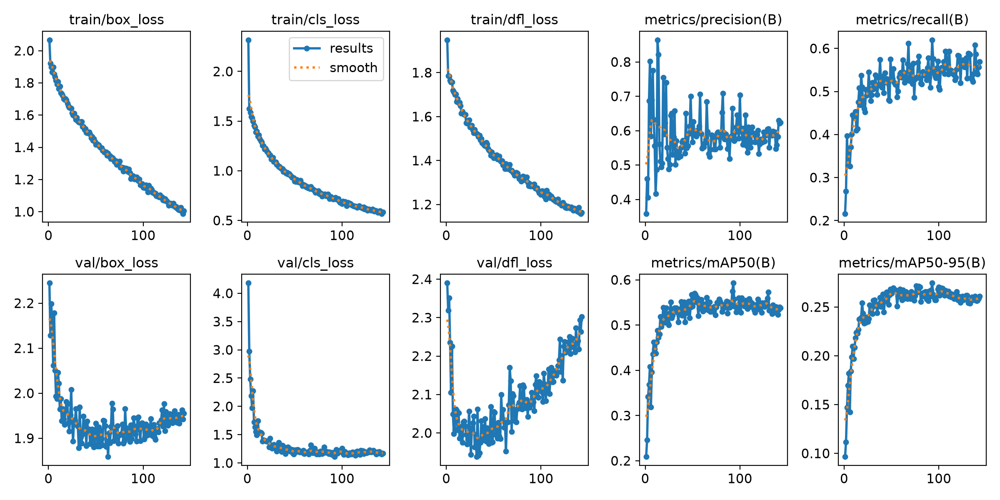

In [42]:
display(IPImage(filename=str(FINAL_DIR / "results.png"), width=1000))

## 6. Evaluasi di data test

Data test tidak pernah dipakai untuk memilih model, jadi angka ini perkiraan jujur performa di dunia nyata.
TTA (*test-time augmentation*: flip dan multi-skala saat prediksi) dicoba sebagai pembanding.
TTA hanya berlaku di Python, tidak di website.

In [43]:
ev = dict(data=DATA_YAML, split=TEST_SPLIT, imgsz=IMGSZ, device=DEVICE, project=str(RUNS), exist_ok=True)
m_test = final_model.val(name="final_test", plots=True, **ev)
m_tta = final_model.val(name="final_test_tta", plots=False, augment=True, verbose=False, **ev)

s_test, s_tta = summarize(final_model, m_test), summarize(final_model, m_tta)
overall = pd.DataFrame({
    "normal": {k: s_test[k] for k in ("precision", "recall", "mAP50", "mAP50_95", "violation_recall")},
    "TTA":    {k: s_tta[k]  for k in ("precision", "recall", "mAP50", "mAP50_95", "violation_recall")},
})
display(overall)

per_class_test = pd.DataFrame(s_test["per_class"]).T.loc[[n for n in NAMES if n in s_test["per_class"]]]
display(per_class_test.style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1).format("{:.3f}"))
(OUT / "test_metrics.json").write_text(json.dumps({"normal": s_test, "tta": s_tta}, indent=2))

Ultralytics 8.4.184  Python-3.14.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32607MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 995.7±770.0 MB/s, size: 71.4 KB)
val: Scanning F:\IRIS\safetycam\training\datasets\construction-ppe\labels\test.cache... 141 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 141/141 49.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.5it/s 6.2s0.1s1
                   all        141       1251      0.614      0.492       0.52      0.261
                helmet        110        192      0.906      0.904      0.922      0.483
                gloves         75        163      0.922      0.728      0.766      0.379
                  vest        111        178      0.856      0.876      0.902      0.564
                 boots         75        211      0.804      0.642      0.744      0

,normal,TTA
precision,0.614,0.591
recall,0.492,0.511
mAP50,0.520,0.535
mAP50_95,0.261,0.266
violation_recall,0.081,0.104


,precision,recall,mAP50,mAP50_95
helmet,0.906,0.904,0.922,0.483
gloves,0.922,0.728,0.766,0.379
vest,0.856,0.876,0.902,0.564
boots,0.804,0.642,0.744,0.392
goggles,0.885,0.738,0.776,0.328
none,0.550,0.400,0.354,0.106
Person,0.832,0.797,0.857,0.496
no_helmet,0.320,0.150,0.202,0.064
no_goggle,0.360,0.103,0.109,0.023
no_gloves,0.318,0.069,0.087,0.031


4406

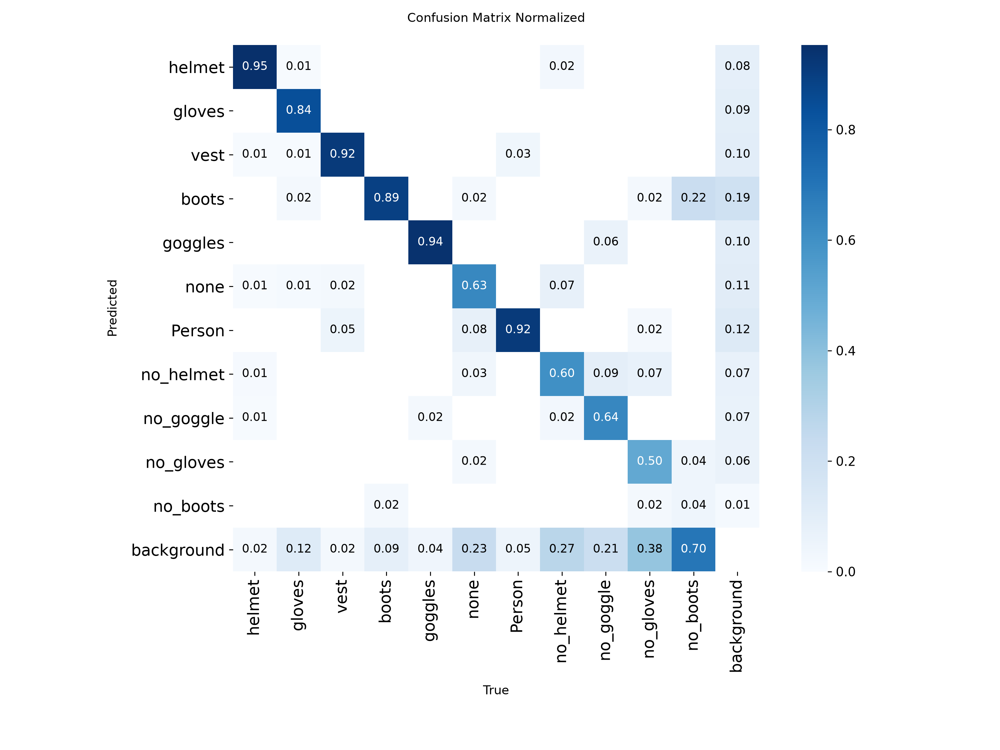

In [44]:
display(IPImage(filename=str(Path(m_test.save_dir) / "confusion_matrix_normalized.png"), width=850))

**Membaca confusion matrix:** perhatikan baris/kolom `background`.
- `no_helmet` sering diprediksi `background` → pelanggaran terlewat.
- `helmet` tertukar dengan `no_helmet` → model bingung di area kepala. Biasanya label ambigu atau objeknya kecil.

## 7. Threshold per kelas

Satu threshold global (misalnya 0.35) belum tentu optimal untuk semua kelas. Di data **val**, untuk setiap kelas dicari
`conf` yang memaksimalkan:
- **F2** untuk kelas `no_*`: recall dihitung 2x lebih penting, karena lebih baik ada alarm palsu daripada pelanggaran terlewat.
- **F1** untuk kelas lain: precision dan recall seimbang.

Kelas yang tidak ada di val memakai 0.35.

Ultralytics 8.4.184  Python-3.14.4 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5090, 32607MiB)
YOLO11s summary (fused): 100 layers, 9,417,057 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1777.1±1165.3 MB/s, size: 194.0 KB)
val: Scanning F:\IRIS\safetycam\training\datasets\construction-ppe\labels\val.cache... 143 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 143/143 60.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 3.8it/s 2.4s<0.2s
                   all        143       1172      0.581      0.623      0.589      0.275
Speed: 0.7ms preprocess, 1.3ms inference, 0.0ms loss, 0.8ms postprocess per image


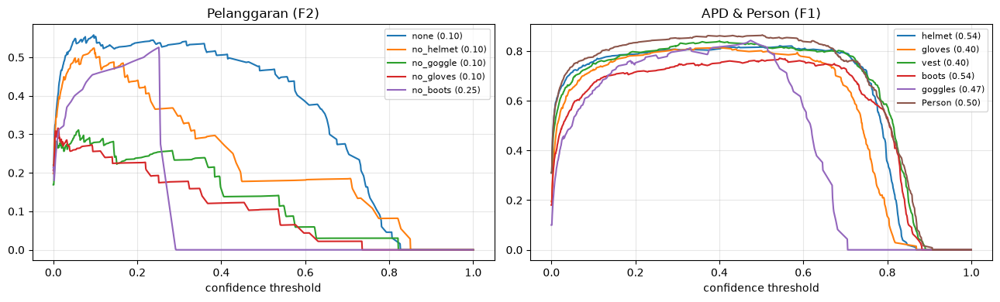

,metrik,conf,precision,recall,skor
kelas,,,,,
helmet,F1,0.544,0.854,0.791,0.821
gloves,F1,0.400,0.880,0.757,0.814
vest,F1,0.400,0.858,0.825,0.841
boots,F1,0.544,0.888,0.682,0.772
goggles,F1,0.474,0.972,0.744,0.843
none,F2,0.100,0.383,0.630,0.558
Person,F1,0.503,0.872,0.858,0.865
no_helmet,F2,0.100,0.321,0.622,0.524
no_goggle,F2,0.100,0.144,0.439,0.311


In [45]:
DEFAULT_CONF = 0.35
m_val = final_model.val(data=DATA_YAML, split="val", imgsz=IMGSZ, device=DEVICE, conf=0.001, plots=False,
                        project=str(RUNS), name="final_val_curves", exist_ok=True, verbose=False)
box = m_val.box
px = np.asarray(box.px)
THRESH, rows = {}, []
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, c in enumerate(box.ap_class_index):
    name = final_model.names[int(c)]
    beta = 2.0 if name in ALARM_CLASSES else 1.0
    p, r = np.asarray(box.p_curve[i]), np.asarray(box.r_curve[i])
    fb = (1 + beta ** 2) * p * r / np.clip(beta ** 2 * p + r, 1e-9, None)
    j = int(np.argmax(fb))
    t = float(np.clip(px[j], 0.10, 0.80))
    THRESH[name] = round(t, 3)
    rows.append(dict(kelas=name, metrik=f"F{beta:g}", conf=round(t, 3), precision=p[j], recall=r[j], skor=fb[j]))
    ax = axes[0] if name in ALARM_CLASSES else axes[1]
    ax.plot(px, fb, label=f"{name} ({t:.2f})")
for ax, title in zip(axes, ("Pelanggaran (F2)", "APD & Person (F1)")):
    ax.set_title(title); ax.set_xlabel("confidence threshold"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

for n in NAMES:
    THRESH.setdefault(n, DEFAULT_CONF)
(OUT / "thresholds.json").write_text(json.dumps(THRESH, indent=2))
pd.DataFrame(rows).set_index("kelas")

## 8. Evaluasi kepatuhan (yang dilihat pengguna)

mAP mengukur ketepatan kotak. Pengguna sebenarnya peduli pada pertanyaan **"apakah gambar ini ada pelanggaran?"**.
Di sini status dari `compliance.py` dibandingkan antara label asli (ground truth) dan prediksi, di data test,
untuk threshold global 0.35 dan threshold per kelas.

In [46]:
def predict_dets(model, paths, thresholds=None, imgsz=640, batch=16):
    # Kembalikan {path: [(name, conf, box)]}, difilter per kelas kalau thresholds diberikan
    lo = min(thresholds.values()) if thresholds else DEFAULT_CONF
    out = {}
    for k in range(0, len(paths), batch):
        for r in model.predict([str(p) for p in paths[k:k + batch]], conf=lo, imgsz=imgsz, device=DEVICE, verbose=False):
            dets = compliance.from_result(r)
            if thresholds:
                dets = [d for d in dets if d[1] >= thresholds.get(d[0], DEFAULT_CONF)]
            out[str(Path(r.path))] = dets
    return out

test_imgs = SPLITS[TEST_SPLIT]
GT = {str(p): gt_detections(p) for p in test_imgs}
PRED = {
    "global 0.35": predict_dets(final_model, test_imgs, None, IMGSZ),
    "per kelas": predict_dets(final_model, test_imgs, THRESH, IMGSZ),
}

def violation_metrics(pred):
    tp = fp = fn = tn = 0
    for p, gt in GT.items():
        g = compliance.assess_detections(gt).status == "PELANGGARAN"
        q = compliance.assess_detections(pred[p]).status == "PELANGGARAN"
        tp += g and q; fp += (not g) and q; fn += g and not q; tn += (not g) and not q
    prec = tp / max(1, tp + fp); rec = tp / max(1, tp + fn)
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, precision=prec, recall=rec,
                F1=2 * prec * rec / max(1e-9, prec + rec), akurasi=(tp + tn) / max(1, len(GT)))

comp = pd.DataFrame({k: violation_metrics(v) for k, v in PRED.items()}).T
print(f"Deteksi 'gambar ini ada pelanggaran' di {TEST_SPLIT} ({len(GT)} gambar)")
display(comp)
print("FN = gambar dengan pelanggaran tapi dianggap aman (paling berbahaya). FP = alarm palsu.")

Deteksi 'gambar ini ada pelanggaran' di test (141 gambar)


,TP,FP,FN,TN,precision,recall,F1,akurasi
global 0.35,28.0,1.0,2.0,110.0,0.966,0.933,0.949,0.979
per kelas,29.0,5.0,1.0,106.0,0.853,0.967,0.906,0.957


FN = gambar dengan pelanggaran tapi dianggap aman (paling berbahaya). FP = alarm palsu.


## 9. Analisis error

Setiap kotak pelanggaran di test dicocokkan dengan prediksi (IoU ≥ 0.5, threshold per kelas).
Gambar dengan pelanggaran terlewat terbanyak ditampilkan: **kiri label asli, kanan prediksi**.
Dari sini biasanya terlihat polanya: objek kecil, terhalang, gelap, atau label yang salah.

,TP,FN,FP,recall,precision
no_helmet,13,27,46,0.325,0.220
no_gloves,7,51,41,0.121,0.146
no_boots,0,23,4,0.000,0.000
no_goggle,11,22,41,0.333,0.212
none,32,33,61,0.492,0.344


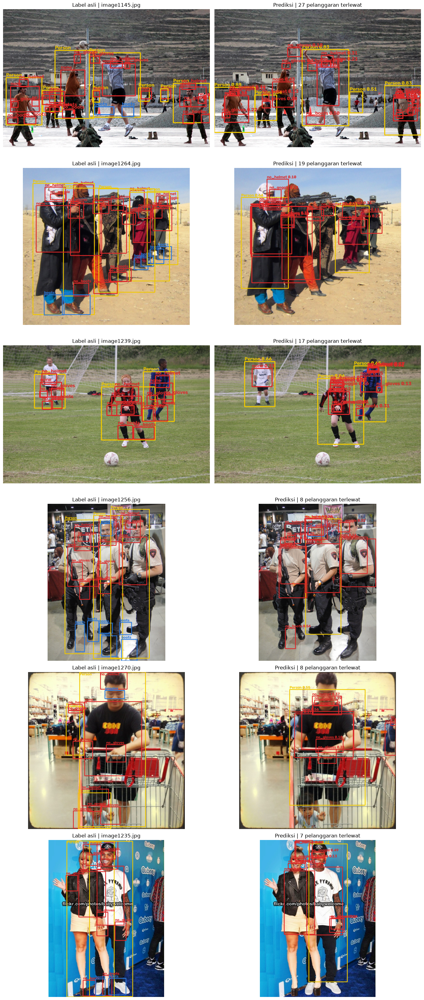

In [47]:
def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (area(a)[:, None] + area(b)[None, :] - inter + 1e-9)

def match(gt_boxes, pr_boxes, thr=0.5):
    m = iou_matrix(gt_boxes, pr_boxes); tp = 0
    while m.size and m.max() >= thr:
        i, j = np.unravel_index(m.argmax(), m.shape)
        tp += 1; m[i, :] = 0; m[:, j] = 0
    return tp, len(gt_boxes) - tp, len(pr_boxes) - tp

pred = PRED["per kelas"]
err = defaultdict(lambda: Counter()); per_img_fn = Counter()
for p, gt in GT.items():
    for c in ALARM_CLASSES:
        g = np.array([b for n, _, b in gt if n == c]).reshape(-1, 4)
        q = np.array([b for n, _, b in pred[p] if n == c]).reshape(-1, 4)
        tp, fn, fp = match(g, q)
        err[c].update(TP=tp, FN=fn, FP=fp); per_img_fn[p] += fn
err_df = pd.DataFrame(err).T.fillna(0).astype(int)
err_df["recall"] = (err_df.TP / (err_df.TP + err_df.FN).clip(lower=1)).round(3)
err_df["precision"] = (err_df.TP / (err_df.TP + err_df.FP).clip(lower=1)).round(3)
display(err_df)

worst = [p for p, n in per_img_fn.most_common(6) if n > 0]
if worst:
    fig, axes = plt.subplots(len(worst), 2, figsize=(14, 5.5 * len(worst)), squeeze=False)
    for (a0, a1), p in zip(axes, worst):
        img = load_rgb(p)
        a0.imshow(draw_boxes(img, GT[p], color_of, is_gt=True)); a0.set_title(f"Label asli | {Path(p).name}")
        a1.imshow(draw_boxes(img, pred[p], color_of)); a1.set_title(f"Prediksi | {per_img_fn[p]} pelanggaran terlewat")
        a0.axis("off"); a1.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Tidak ada pelanggaran yang terlewat di test.")

## 9b. Evaluasi per pekerja: detektor `no_*` vs absen APD

Deteksi APD yang **dipakai** sangat kuat (helm dan rompi mAP50 ≈ 0.9), tapi detektor `no_*` lemah.
Di sini dibandingkan dua cara menentukan pelanggaran **untuk setiap pekerja**:

| Cara | Pekerja dianggap melanggar item X kalau… |
|---|---|
| **detektor** (cara sekarang) | ada kotak `no_X` (atau `none` untuk rompi) di dalam kotak pekerja |
| **absen** | pekerja terdeteksi, cukup besar di gambar (`min_h`), dan **tidak ada** kotak X di dalamnya |

Untuk cara **absen**, pekerja yang terlalu kecil di gambar tetap memakai cara detektor, karena APD-nya sulit terlihat.

**Cara menilai:**
- Pekerja hasil prediksi dicocokkan dengan pekerja di label asli (IoU kotak Person ≥ 0.5).
- Untuk setiap item, pekerja di label asli bisa **melanggar** (ada `no_X`), **patuh** (ada X), atau **tak dinilai** (tidak ada keduanya).
- Pekerja melanggar yang tidak terdeteksi sama sekali dihitung FN.
- Pekerja palsu yang ditandai melanggar dihitung FP.
- Parameter `worn_conf` (threshold APD dipakai) dan `min_h` (tinggi minimal pekerja, relatif terhadap tinggi gambar) dipilih per item di **val** dengan F2, lalu hasilnya diukur di **test**.

In [48]:
EVAL_ITEMS = ["helmet", "vest", "gloves", "boots", "goggles"]

def build_maps(paths):
    gt = {str(p): gt_detections(p) for p in paths}
    raw = predict_dets(final_model, paths, {n: 0.10 for n in NAMES}, IMGSZ)  # semua deteksi conf >= 0.10
    sizes = {str(p): exif_size(Image.open(p)) for p in paths}
    return gt, raw, sizes

GT_VAL, RAW_VAL, SIZE_VAL = build_maps(SPLITS["val"])
GT_TEST, RAW_TEST, SIZE_TEST = build_maps(test_imgs)

def match_workers(gw, pw, thr=0.5):
    m = iou_matrix(np.array([w.box for w in gw]).reshape(-1, 4), np.array([w.box for w in pw]).reshape(-1, 4))
    pairs = []
    while m.size and m.max() >= thr:
        i, j = np.unravel_index(m.argmax(), m.shape)
        pairs.append((int(i), int(j))); m[i, :] = 0; m[:, j] = 0
    return pairs

def worker_flags(dets_raw, img_h, cfg):
    # cfg: {item: dict(method="detektor") | dict(method="absen", worn_conf=.., min_h=..)}
    thr = dict(THRESH)
    for it, c in cfg.items():
        if c["method"] == "absen":
            thr[it] = c["worn_conf"]
    rep = compliance.assess_detections([d for d in dets_raw if d[1] >= thr.get(d[0], 1.0)])
    flags = []
    for w in rep.workers:
        f = set()
        for it, c in cfg.items():
            if c["method"] == "absen" and (w.box[3] - w.box[1]) >= c["min_h"] * img_h:
                if it not in w.worn:
                    f.add(it)
            elif it in w.missing:
                f.add(it)
        flags.append(f)
    return rep, flags

def eval_item(item, c, gt_map, raw_map, size_map):
    s = Counter()
    for p in gt_map:
        gw = compliance.assess_detections(gt_map[p]).workers
        rep, flags = worker_flags(raw_map[p], size_map[p][1], {item: c})
        pw = rep.workers
        pairs = match_workers(gw, pw)
        mg, mp = {i for i, _ in pairs}, {j for _, j in pairs}
        for i, j in pairs:
            g = gw[i]
            truth = True if item in g.missing else (False if item in g.worn else None)
            if truth is None:
                s["tak dinilai"] += 1
                continue
            pred = item in flags[j]
            s["TP" if truth and pred else "FN" if truth else "FP" if pred else "TN"] += 1
        for i in range(len(gw)):
            if i not in mg and item in gw[i].missing:
                s["FN"] += 1; s["FN pekerja tak terdeteksi"] += 1
        for j in range(len(pw)):
            if j not in mp and item in flags[j]:
                s["FP"] += 1; s["FP pekerja palsu"] += 1
    tp, fp, fn = s["TP"], s["FP"], s["FN"]
    prec, rec = tp / max(1, tp + fp), tp / max(1, tp + fn)
    f = lambda b: (1 + b * b) * prec * rec / max(1e-9, b * b * prec + rec)
    return dict(TP=tp, FP=fp, FN=fn, TN=s["TN"], precision=prec, recall=rec, F1=f(1), F2=f(2),
                **{"tak dinilai": s["tak dinilai"], "FN tak terdeteksi": s["FN pekerja tak terdeteksi"]})

print(f"val: {len(GT_VAL)} gambar | test: {len(GT_TEST)} gambar")

val: 143 gambar | test: 141 gambar


### Pilih parameter di val (F2 per item)

In [49]:
OPTIONS = [dict(method="detektor")] + [
    dict(method="absen", worn_conf=wc, min_h=mh)
    for wc in (0.15, 0.25, 0.35, 0.45) for mh in (0.0, 0.1, 0.2, 0.3)
]

def opt_name(c):
    return "detektor no_*" if c["method"] == "detektor" else f"absen (conf {c['worn_conf']}, min_h {c['min_h']})"

BEST_CFG, val_rows = {}, []
for item in EVAL_ITEMS:
    res = [(c, eval_item(item, c, GT_VAL, RAW_VAL, SIZE_VAL)) for c in OPTIONS]
    det = res[0]
    best_abs = max(res[1:], key=lambda r: r[1]["F2"])
    best = max([det, best_abs], key=lambda r: r[1]["F2"])
    BEST_CFG[item] = best[0]
    for tag, (c, m) in (("detektor", det), ("absen terbaik", best_abs)):
        val_rows.append({"item": item, "cara": opt_name(c), **{k: m[k] for k in ("TP", "FP", "FN", "precision", "recall", "F2")},
                         "dipilih": "✅" if c is best[0] else ""})
val_df = pd.DataFrame(val_rows).set_index(["item", "cara"])
display(val_df.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "F2": "{:.3f}"}))
print("Konfigurasi terpilih:", {k: opt_name(v) for k, v in BEST_CFG.items()})

Konfigurasi terpilih: {'helmet': 'absen (conf 0.15, min_h 0.3)', 'vest': 'absen (conf 0.15, min_h 0.0)', 'gloves': 'absen (conf 0.15, min_h 0.3)', 'boots': 'absen (conf 0.15, min_h 0.3)', 'goggles': 'detektor no_*'}


### Hasil di test (per pekerja)

In [50]:
DET_CFG = {it: dict(method="detektor") for it in EVAL_ITEMS}
test_rows = []
for item in EVAL_ITEMS:
    for tag, c in (("detektor no_*", DET_CFG[item]), ("terpilih: " + opt_name(BEST_CFG[item]), BEST_CFG[item])):
        m = eval_item(item, c, GT_TEST, RAW_TEST, SIZE_TEST)
        test_rows.append({"item": item, "cara": tag, **m})
test_df = pd.DataFrame(test_rows).set_index(["item", "cara"])
cols = ["TP", "FP", "FN", "TN", "precision", "recall", "F1", "F2", "tak dinilai", "FN tak terdeteksi"]
display(test_df[cols].style.format({k: "{:.3f}" for k in ("precision", "recall", "F1", "F2")}))
test_df.to_csv(OUT / "worker_eval_test.csv")
(OUT / "worker_rules.json").write_text(json.dumps(BEST_CFG, indent=2))

372

### Dampak ke status per gambar (sama seperti bagian 8)

Ini membandingkan status "gambar ini ada pelanggaran" di test, kalau aturan per item terpilih dipakai.
Baris `detektor no_*` harus sama dengan baris **per kelas** di bagian 8, sebagai cek kewarasan.

In [51]:
def image_level(cfg):
    tp = fp = fn = tn = 0
    for p in GT_TEST:
        g = compliance.assess_detections(GT_TEST[p]).status == "PELANGGARAN"
        rep, flags = worker_flags(RAW_TEST[p], SIZE_TEST[p][1], cfg)
        q = any(flags) or any(n in compliance.MISSING for n, _ in rep.unassigned)
        tp += g and q; fp += (not g) and q; fn += g and not q; tn += (not g) and not q
    prec, rec = tp / max(1, tp + fp), tp / max(1, tp + fn)
    return dict(TP=tp, FP=fp, FN=fn, TN=tn, precision=prec, recall=rec,
                F1=2 * prec * rec / max(1e-9, prec + rec), akurasi=(tp + tn) / max(1, len(GT_TEST)))

img_cmp = pd.DataFrame({
    "detektor no_* (= bagian 8)": image_level(DET_CFG),
    "aturan terpilih per item": image_level(BEST_CFG),
}).T
display(img_cmp)

,TP,FP,FN,TN,precision,recall,F1,akurasi
detektor no_* (= bagian 8),29.0,5.0,1.0,106.0,0.853,0.967,0.906,0.957
aturan terpilih per item,30.0,51.0,0.0,60.0,0.370,1.000,0.541,0.638


**Cara membaca:**
- Kalau **absen** terpilih untuk helm/rompi dan recall-nya di test jauh lebih tinggi dengan precision yang masih wajar, aturan ini layak dipindahkan ke `compliance.py` dan website.
- `tak dinilai` = pekerja yang di label asli tidak punya label X maupun `no_X` (misalnya kaki terpotong frame). Pekerja ini tidak ikut dihitung.
- `FN tak terdeteksi` = pekerja melanggar yang kotak Person-nya tidak terdeteksi sama sekali. Ini tidak bisa diperbaiki dengan aturan, hanya dengan model.

### Kalau hasilnya belum memuaskan

| Gejala | Coba |
|---|---|
| Recall `no_*` rendah, objeknya kecil | `imgsz=960`, atau model `s`/`m` |
| Recall `no_*` rendah, objeknya besar | naikkan `rfs_threshold` (0.5) atau `rfs_max_repeat` (6) |
| Train bagus, val jelek (overfit) | model lebih kecil, `mixup=0.2`, tambah data |
| `helmet` ↔ `no_helmet` tertukar | cek label di analisis error. Label salah lebih merusak daripada data kurang |
| Gagal di foto proyekmu sendiri | **tambah ±100–300 foto lokal yang dilabeli**, ini peningkatan paling besar untuk dunia nyata |

## 10. Simpan & export ke website

- Menyalin model final ke `weights/best.pt`.
- Menjalankan `evaluate.py` untuk metrik di website.
- Menjalankan `export.py` untuk membuat `../web/model/best.onnx`.
- Menyalin `thresholds.json` ke `../web/model/`. Catatan: website saat ini masih memakai satu threshold dari slider.

In [52]:
EXPORT = True
if EXPORT:
    if IMGSZ != 640:
        print(f"PERINGATAN: model dilatih di imgsz {IMGSZ}, website memakai 640. Akurasinya di website bisa turun.")
    (ROOT / "weights").mkdir(exist_ok=True)
    shutil.copy2(FINAL_WEIGHTS, ROOT / "weights" / "best.pt")
    shutil.copy2(OUT / "thresholds.json", ROOT / "weights" / "thresholds.json")
    subprocess.run([sys.executable, "evaluate.py", "--device", str(DEVICE), "--imgsz", str(IMGSZ)], check=True, cwd=ROOT)
    subprocess.run([sys.executable, "export.py", "--imgsz", "640"], check=True, cwd=ROOT)
    web_model = ROOT.parent / "web" / "model"
    shutil.copy2(OUT / "thresholds.json", web_model / "thresholds.json")
    for f in sorted(web_model.iterdir()):
        print(f"{f.name:20s} {f.stat().st_size / 1e6:6.1f} MB")

best.onnx              37.9 MB
classes.json            0.0 MB
metrics.json            0.0 MB
thresholds.json         0.0 MB
